# Previsão de vendas do varejo de material de construção

**Pergunta de negócio:** quanto o varejo de material de construção vai vender nos próximos 12 meses?

Para um home center, essa previsão orienta compras, estoque, escala de equipes e metas. Este notebook usa o
índice de volume de vendas do varejo de material de construção no Brasil, da Pesquisa Mensal de Comércio do
IBGE, para responder essa pergunta e comparar modelos de previsão com uma validação que simula o uso real.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

sys.path.insert(0, "../src")
from modelos import carregar_serie, features_calendario

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
serie = carregar_serie("../data/processed/material_construcao_brasil.csv")
print(f"{len(serie)} meses, de {serie.index[0]:%m/%Y} a {serie.index[-1]:%m/%Y}")
serie.tail()

283 meses, de 01/2003 a 07/2026


data
2026-03-01    107.98037
2026-04-01     98.52962
2026-05-01    104.64314
2026-06-01     98.00336
2026-07-01    106.98296
Freq: MS, Name: indice, dtype: float64

## 1. Dados

- **Fonte:** IBGE, PMC, tabela 8883 (comércio varejista ampliado, por atividades)
- **Variável:** índice de volume de vendas de material de construção, base 2022 = 100, **sem ajuste sazonal**
- **Período:** janeiro de 2003 a julho de 2026, sem meses faltantes

O índice de **volume** mede a quantidade vendida, sem o efeito da inflação. A série sem ajuste sazonal foi
escolhida de propósito: a sazonalidade é parte do que queremos prever.

O arquivo bruto do IBGE vem em formato largo (um mês por coluna); a conversão para a série mensal está em
`data/processed/`.

## 2. Análise exploratória

### Tendência e choques

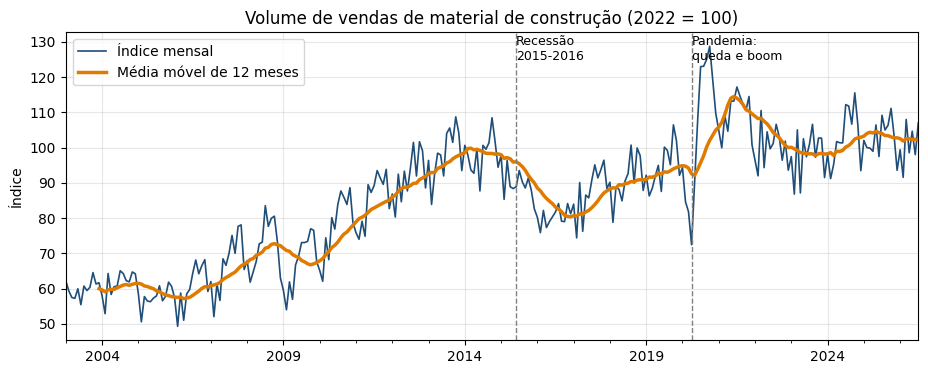

Variação anual do volume (%), 2026 até julho:
data
2019     4.2
2020    10.8
2021     4.4
2022    -8.7
2023    -1.8
2024     4.8
2025    -0.1
2026    -1.7


In [2]:
ax = serie.plot(color="#1f4e79", lw=1.2, label="Índice mensal")
serie.rolling(12).mean().plot(ax=ax, color="#e07b00", lw=2.5, label="Média móvel de 12 meses")
for data, texto in [("2015-06", "Recessão\n2015-2016"), ("2020-04", "Pandemia:\nqueda e boom")]:
    ax.axvline(pd.Timestamp(data), color="gray", ls="--", lw=1)
    ax.text(pd.Timestamp(data), serie.max() * 0.97, texto, fontsize=9, ha="left")
ax.set(title="Volume de vendas de material de construção (2022 = 100)", ylabel="Índice", xlabel="")
ax.legend(); plt.show()

anual = serie.resample("YS").mean()
print("Variação anual do volume (%), 2026 até julho:")
print((anual.pct_change() * 100).round(1).rename(lambda d: d.year).tail(8).to_string())

**Leitura:** a série cresce até 2013-2014, cai com a recessão de 2015-2016 e tem o maior pico da história
em 2020-2021, quando as pessoas passaram mais tempo em casa e investiram em reformas. Depois do pico, as vendas
voltaram a um patamar estável, perto de 100. Esses choques são o maior desafio para qualquer modelo.

### Sazonalidade

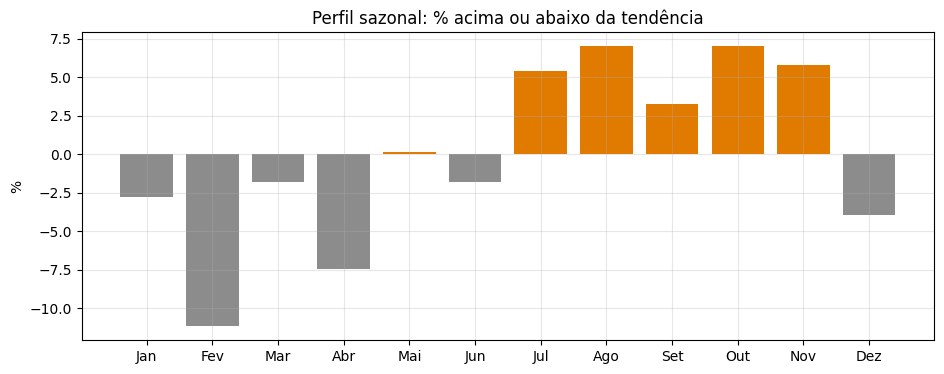

Força da sazonalidade: 0.67 (0 = nenhuma, 1 = muito forte)


In [3]:
stl = STL(serie, period=12, robust=True).fit()
perfil = ((serie / stl.trend).groupby(serie.index.month).mean() - 1) * 100
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
plt.bar(meses, perfil.values, color=["#e07b00" if v > 0 else "#8c8c8c" for v in perfil.values])
plt.title("Perfil sazonal: % acima ou abaixo da tendência"); plt.ylabel("%"); plt.show()

forca = 1 - np.var(stl.resid) / np.var(stl.resid + stl.seasonal)
print(f"Força da sazonalidade: {forca:.2f} (0 = nenhuma, 1 = muito forte)")

**Leitura:** de julho a novembro as vendas ficam de 3% a 7% acima da tendência; fevereiro é o mês mais
fraco, cerca de 11% abaixo. Uma hipótese é que parte dessa diferença venha do **calendário**: fevereiro tem
menos dias e, em geral, menos dias úteis.

### O calendário explica parte da variação?

In [4]:
cal = features_calendario(serie.index)
desvio = (serie / stl.trend - 1) * 100
for coluna in ["dias_uteis", "sabados"]:
    media = desvio.groupby(cal[coluna]).mean().round(1)
    print(f"Desvio médio da tendência (%) por número de {coluna.replace('_', ' ')}:", media.to_dict())

Desvio médio da tendência (%) por número de dias uteis: {20: -8.0, 21: -1.7, 22: 1.1, 23: 3.6}
Desvio médio da tendência (%) por número de sabados: {4: 0.2, 5: -0.7}


**Leitura:** a relação com os dias úteis é clara: meses com 20 dias úteis ficam cerca de 8% abaixo da
tendência, e meses com 23 ficam cerca de 4% acima. Para os sábados, a comparação simples não mostra diferença,
porque meses com 5 sábados costumam ter menos dias úteis e um efeito esconde o outro. Por isso as duas
variáveis entram **juntas** no modelo SARIMA, que separa o efeito de cada uma. Mais adiante, medimos se isso
realmente melhora a previsão.

## 3. Estratégia de validação

Em séries temporais, embaralhar os dados faz o modelo "ver o futuro" e infla os resultados. Por isso a
validação usa **origem móvel**: em 6 pontos de corte semestrais (de jan/2023 a jul/2025), cada modelo é
treinado só com o passado e prevê os 12 meses seguintes, que são comparados com o que realmente aconteceu.

A métrica principal é o **MAPE** (erro percentual absoluto médio), fácil de comunicar para o negócio.

### Modelos comparados

| Modelo | Ideia |
|---|---|
| Sazonal ingênuo | Repete o mesmo mês do ano anterior. É a **linha de base**: um modelo só vale a pena se for melhor que ela |
| Holt-Winters | Suavização exponencial com tendência amortecida e sazonalidade multiplicativa |
| SARIMA | ARIMA sazonal sobre o log da série, com dias úteis e sábados como variáveis externas; ordem escolhida pelo AIC |
| SARIMA sem calendário | O mesmo modelo sem as variáveis de calendário, para medir o ganho delas |
| LightGBM | Machine learning com defasagens, médias móveis e calendário, prevendo a variação anual |
| Combinação | Média das previsões de Holt-Winters, SARIMA e LightGBM |

O código está em `src/modelos.py` e a validação em `src/avaliacao.py`. Os resultados abaixo foram gerados
por esse script.

## 4. Resultados

In [5]:
resumo = pd.read_csv("../data/resultados/validacao_resumo.csv", index_col="modelo")
resumo

,MAPE,RMSE,MAPE_desvio,ganho_vs_linha_de_base_%
modelo,,,,
SARIMA,3.37,4.30,0.66,24.94
Combinação (média dos 3 modelos),3.40,4.48,1.20,24.22
Holt-Winters,3.61,4.48,0.54,19.55
SARIMA sem calendário,3.66,4.57,0.57,18.47
Sazonal ingênuo (linha de base),4.48,5.66,1.32,0.00
LightGBM,5.61,6.93,1.54,-25.17


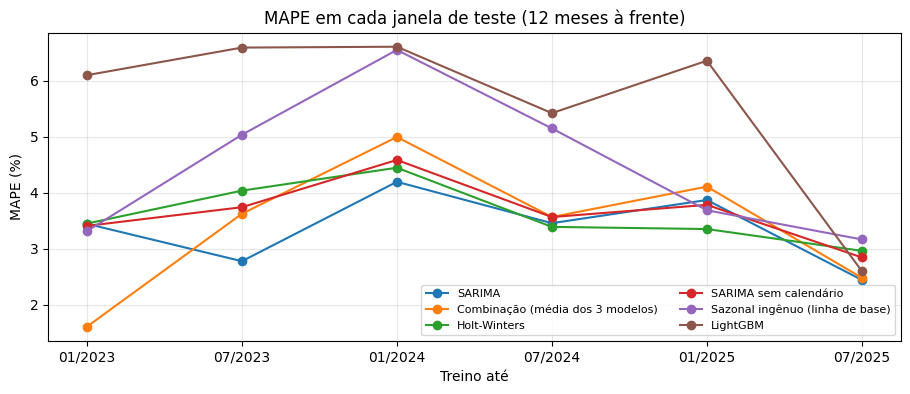

In [6]:
janelas = pd.read_csv("../data/resultados/validacao_por_janela.csv", parse_dates=["corte"])
tabela = janelas.pivot(index="corte", columns="modelo", values="MAPE")
tabela.index = tabela.index.strftime("%m/%Y")
ax = tabela[resumo.index].plot(marker="o")
ax.set(title="MAPE em cada janela de teste (12 meses à frente)", xlabel="Treino até", ylabel="MAPE (%)")
ax.legend(fontsize=8, ncol=2); plt.show()

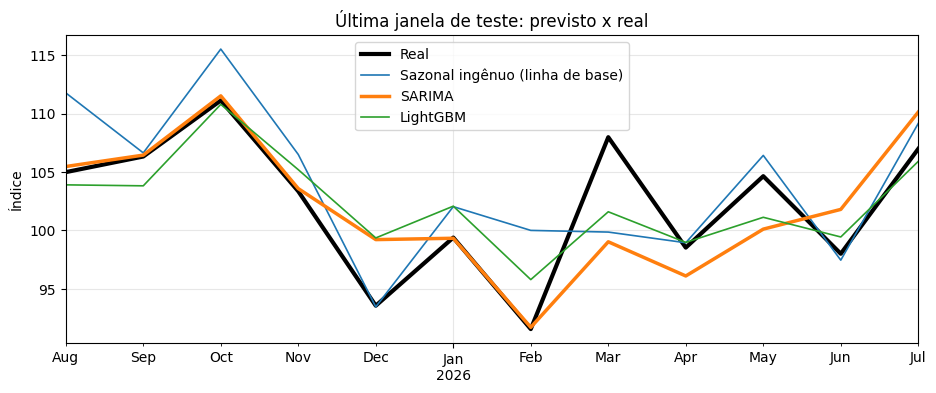

In [7]:
previsoes = pd.read_csv("../data/resultados/validacao_previsoes.csv", parse_dates=["corte", "data"])
ultima = previsoes[previsoes.corte == previsoes.corte.max()]
real = ultima.drop_duplicates("data").set_index("data")["real"]
ax = real.plot(color="black", lw=3, label="Real")
for modelo in ["Sazonal ingênuo (linha de base)", "SARIMA", "LightGBM"]:
    g = ultima[ultima.modelo == modelo].set_index("data")["previsto"]
    g.plot(ax=ax, lw=2.5 if modelo == "SARIMA" else 1.2, label=modelo)
ax.set(title="Última janela de teste: previsto x real", ylabel="Índice", xlabel=""); ax.legend(); plt.show()

In [8]:
import json
info = json.load(open("../data/resultados/modelo_final.json"))
print(f"Modelo final: SARIMA{tuple(info['ordem'])}x{tuple(info['ordem_sazonal'])}")
print(f"Cada dia útil a mais no mês: {info['efeito_dia_util_%']:+.1f}% no volume de vendas")
print(f"Cada sábado a mais no mês (mantidos os dias úteis): {info['efeito_sabado_%']:+.1f}%")

Modelo final: SARIMA(1, 1, 0)x(1, 1, 1, 12)
Cada dia útil a mais no mês: +3.2% no volume de vendas
Cada sábado a mais no mês (mantidos os dias úteis): +1.5%


### O que os resultados mostram

- O **SARIMA com calendário** teve o menor erro médio e foi o escolhido como modelo final.
- **As variáveis de calendário importam:** sem elas, o mesmo SARIMA erra mais (MAPE de 3,66% contra 3,37%,
  cerca de 8% a mais de erro). Cada dia útil a mais soma cerca de 3% ao volume do mês, e cada sábado, cerca de
  1,5%, o que confirma a hipótese levantada na análise exploratória.
- O **LightGBM ficou pior que a linha de base.** Com cerca de 280 observações mensais, há poucos dados para um
  modelo de árvores aprender padrões que os modelos estatísticos já capturam bem. É um lembrete de que o
  modelo mais sofisticado nem sempre é o melhor.
- A **combinação** de modelos chega perto do SARIMA, mas não o supera.

## 5. Previsão para os próximos 12 meses

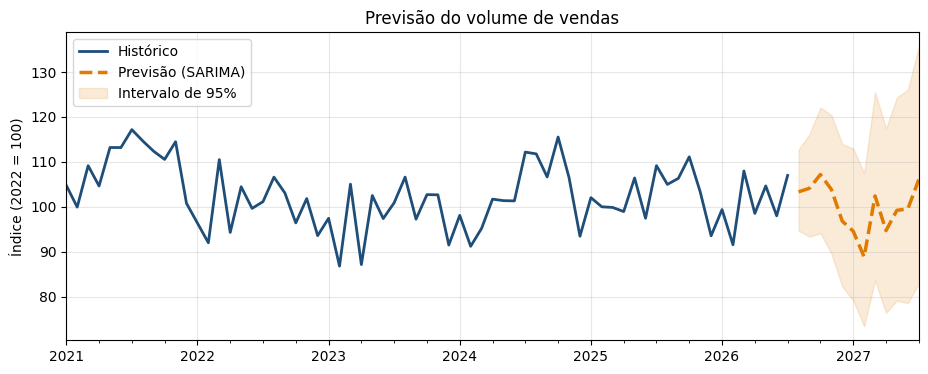

Média prevista: 100.1 (-2.1% em relação aos últimos 12 meses)


,previsao,limite_inferior,limite_superior
data,,,
2026-08-01,103.3,94.7,112.8
2026-09-01,104.1,93.4,116.1
2026-10-01,107.2,94.1,122.1
2026-11-01,103.9,89.6,120.4
2026-12-01,96.8,82.2,114.0
2027-01-01,94.6,79.2,113.0
2027-02-01,88.8,73.4,107.5
2027-03-01,102.4,83.6,125.5
2027-04-01,94.7,76.4,117.4


In [9]:
futuro = pd.read_csv("../data/resultados/previsao_12_meses.csv", parse_dates=["data"]).set_index("data")
hist = serie["2021":]
ax = hist.plot(color="#1f4e79", lw=2, label="Histórico")
futuro["previsao"].plot(ax=ax, color="#e07b00", lw=2.5, ls="--", label="Previsão (SARIMA)")
ax.fill_between(futuro.index, futuro.limite_inferior, futuro.limite_superior, color="#e07b00", alpha=0.15,
                label="Intervalo de 95%")
ax.set(title="Previsão do volume de vendas", ylabel="Índice (2022 = 100)", xlabel=""); ax.legend(); plt.show()

variacao = (futuro.previsao.mean() / serie.iloc[-12:].mean() - 1) * 100
print(f"Média prevista: {futuro.previsao.mean():.1f} ({variacao:+.1f}% em relação aos últimos 12 meses)")
futuro.round(1)

## 6. Conclusões

- Para planejamento de compras e estoque, o SARIMA com calendário oferece uma previsão com erro médio na faixa
  de 3% a 4% para os 12 meses seguintes, cerca de 25% melhor que repetir o ano anterior.
- A previsão aponta para uma **leve retração**, de cerca de 2% em relação aos últimos 12 meses, mantendo a
  sazonalidade: segundo semestre mais forte e fevereiro como mês mais fraco.
- O intervalo de confiança se abre com o horizonte. Para decisões de longo prazo, a recomendação é atualizar a
  previsão todo mês, assim que o IBGE divulgar um novo dado.

## 7. Limitações e próximos passos

- O índice é nacional; o comportamento de um estado ou de uma loja específica pode ser diferente.
- Choques como a pandemia não são previsíveis pelo histórico. Uma evolução seria incluir variáveis econômicas,
  como juros, crédito imobiliário e emprego.
- Os feriados nacionais (Carnaval, por exemplo) ainda não entram no cálculo de dias úteis.
- A validação usa 6 janelas; mais janelas dariam uma estimativa de erro mais robusta.